### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DPNM = data.copy()
DPNM = DPNM[DPNM['category']=='pulses and nuts']
DPNM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
16,1/15/2008,Rakhine,Maungdaw,Alel Than Kyaw,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,650.0,0.3652
19,1/15/2008,Rakhine,Maungdaw,Buthidaung,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,600.0,0.3371
22,1/15/2008,Rakhine,Maungdaw,Kyein Chung,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,500.0,0.2809
25,1/15/2008,Rakhine,Maungdaw,Maungdaw,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,570.0,0.3202
28,1/15/2008,Rakhine,Maungdaw,Myin Hlut,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,450.0,0.2528


In [13]:
DPNM = DPNM[['date', 'price']]
DPNM['date'] = pd.to_datetime(DPNM['date'])
mask = (DPNM['date']>=obv_st_date) & (DPNM['date']<=obv_end_date)
DPNM = DPNM.loc[mask]
DPNM = DPNM.set_index('date')
DPNM.head()

,price
date,
2008-01-15,650.0
2008-01-15,600.0
2008-01-15,500.0
2008-01-15,570.0
2008-01-15,450.0


In [14]:
DPNM = DPNM.resample('MS').mean()
DPNM.head()

,price
date,
2008-01-01,623.095714
2008-02-01,800.952143
2008-03-01,835.064286
2008-04-01,597.618571
2008-05-01,531.092857


In [15]:
DPNM.shape

(169, 1)

In [16]:
price = DPNM['price']
date = DPNM.index

##### Normalization data

In [17]:
scaler = MinMaxScaler()

In [18]:
DPNM = scaler.fit_transform(DPNM)
DPNM = pd.DataFrame(DPNM)
DPNM.head()

,0
0,0.052446
1,0.153832
2,0.173278
3,0.037923
4,0.000000


In [19]:
DPNM['date']=date
DPNM = DPNM.set_index('date')
DPNM.columns=['price']
DPNM.head()

,price
date,
2008-01-01,0.052446
2008-02-01,0.153832
2008-03-01,0.173278
2008-04-01,0.037923
2008-05-01,0.000000


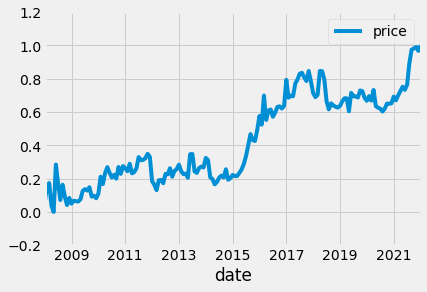

In [20]:
DPNM.plot(grid=True)
plt.show()

It has positive trend.

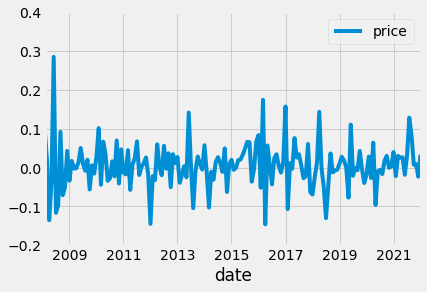

In [21]:
DPNM_diff1 = DPNM.diff(1).dropna()
DPNM_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [22]:
RW_DPNM= adfuller(DPNM_diff1)
RW_DPNM[1] # print P-value. If p-value<5%, reject null hypothesis

1.2498850271734752e-28

<span style="color:red">Are there any external factors that may influence this price?</span>

##### Plotting ACF and PACF

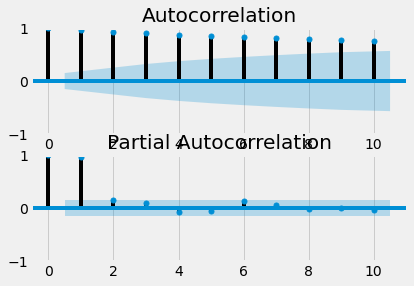

In [23]:
fig, axes=plt.subplots(2,1)
plot_acf(DPNM, lags=10, ax=axes[0])
plot_pacf(DPNM, lags=10, ax=axes[1])
plt.show()

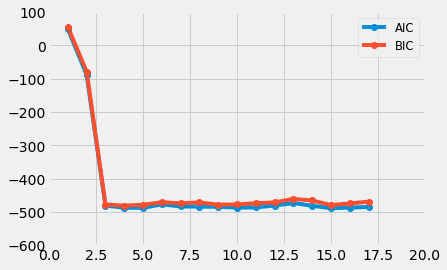

In [24]:
AIC, BIC = AIC_BIC_withOrderRange(DPNM, p=3, d=2, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 
# 6:(1,0,0), 7:(1,0,1), 8:(1,0,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 
# 12:(2,0,0), 13:(2,0,1), 14:(2,0,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [25]:
AIC, BIC

(array([ 250.61162357,   49.30848934,  -88.34061635, -480.706497  ,
        -487.2842257 , -487.80647888, -477.00687025, -483.37212157,
        -483.856116  , -484.48064548, -486.69731839, -486.37228085,
        -480.64494866, -473.23479547, -481.10151532, -488.78367711,
        -486.80297509, -484.80466691]),
 array([ 253.74152229,   55.56828677,  -78.9509202 , -477.58253302,
        -481.03629774, -478.43458694, -470.74707282, -473.98242543,
        -471.33652114, -478.23271752, -477.32542645, -473.87642494,
        -471.25525251, -460.71520061, -465.45202175, -479.41178517,
        -474.30711917, -469.18484701]))

We will run again 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [26]:
mod_orders = [
    (0,1,0), 
    (0,1,1), 
    (0,1,2), 
    (1,1,0), 
    (1,1,1), 
    (1,1,2), 
    (2,1,0), 
    (2,1,1), 
    (2,1,2)
]

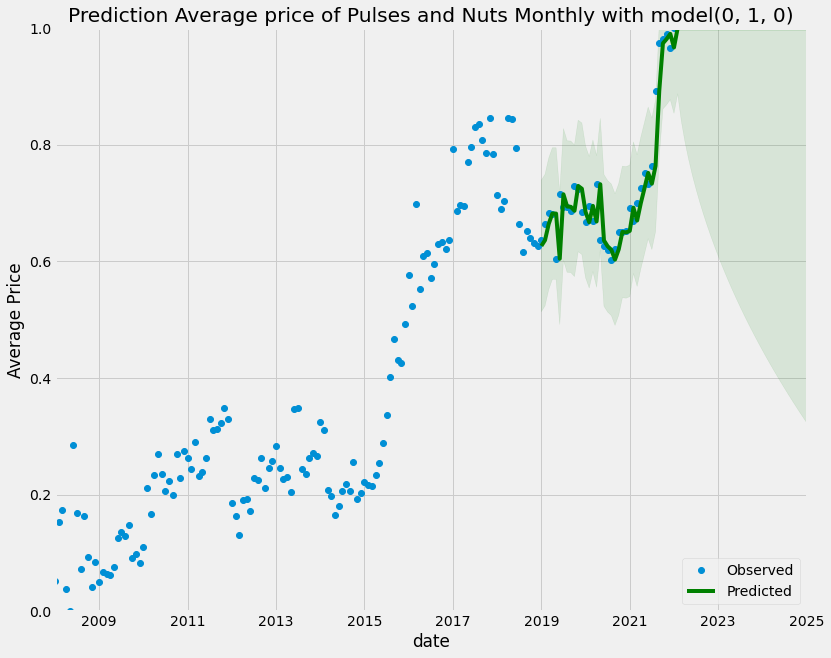

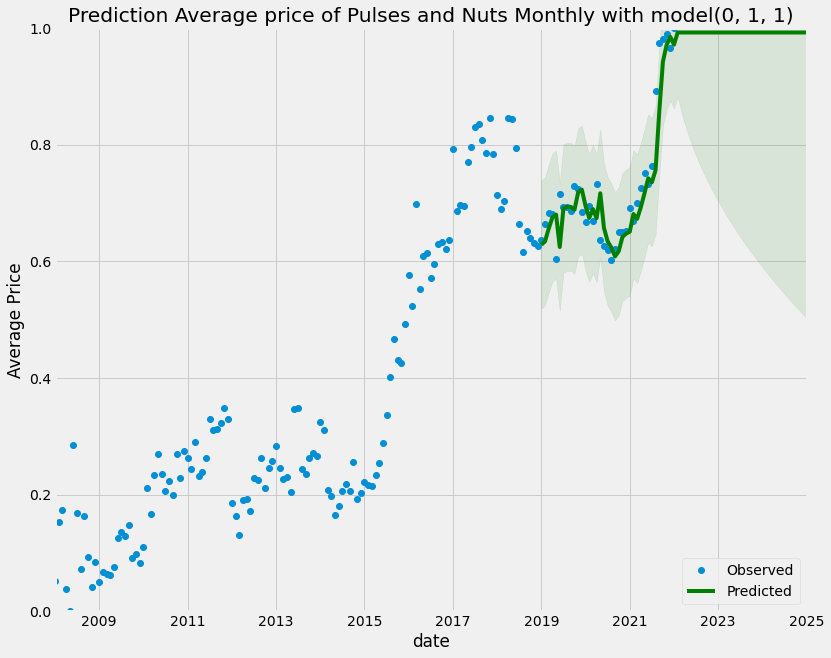

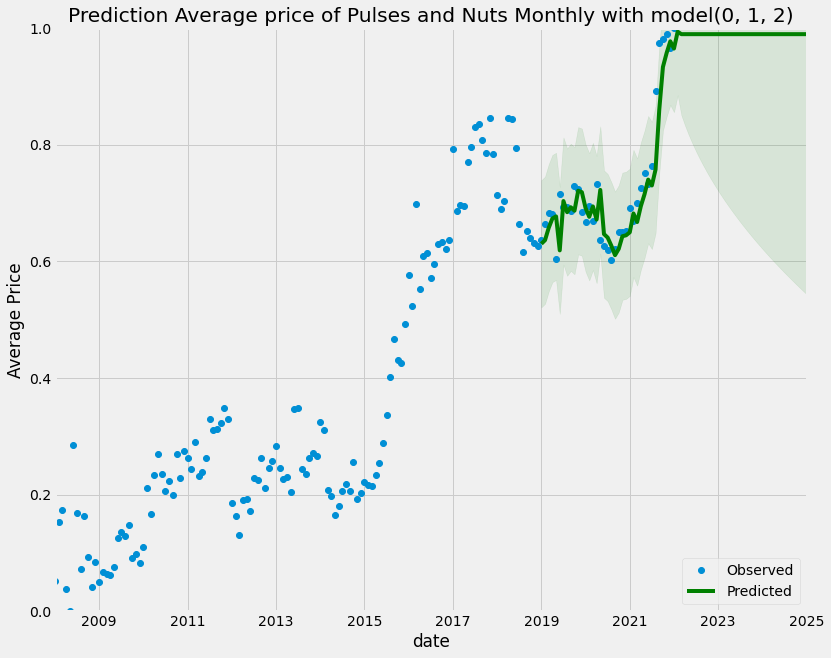

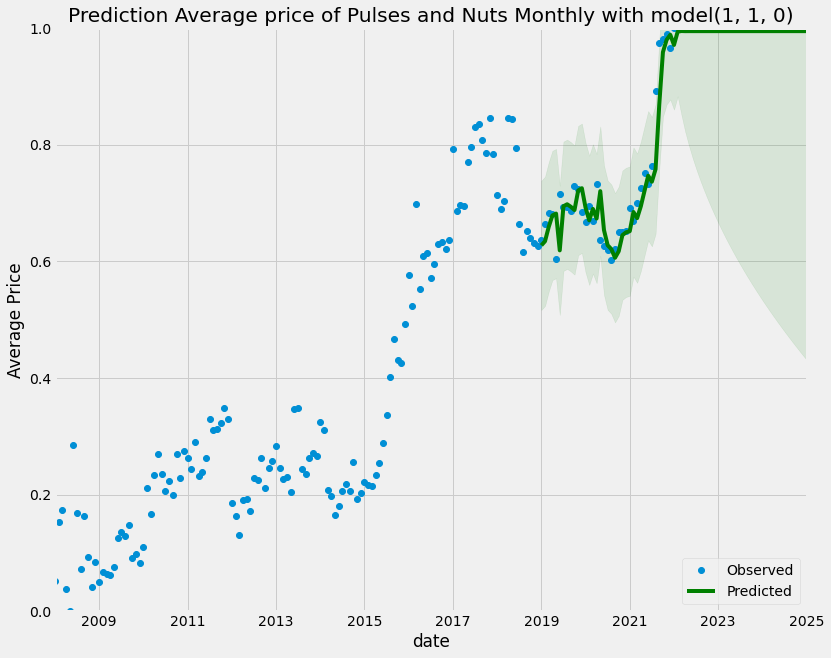

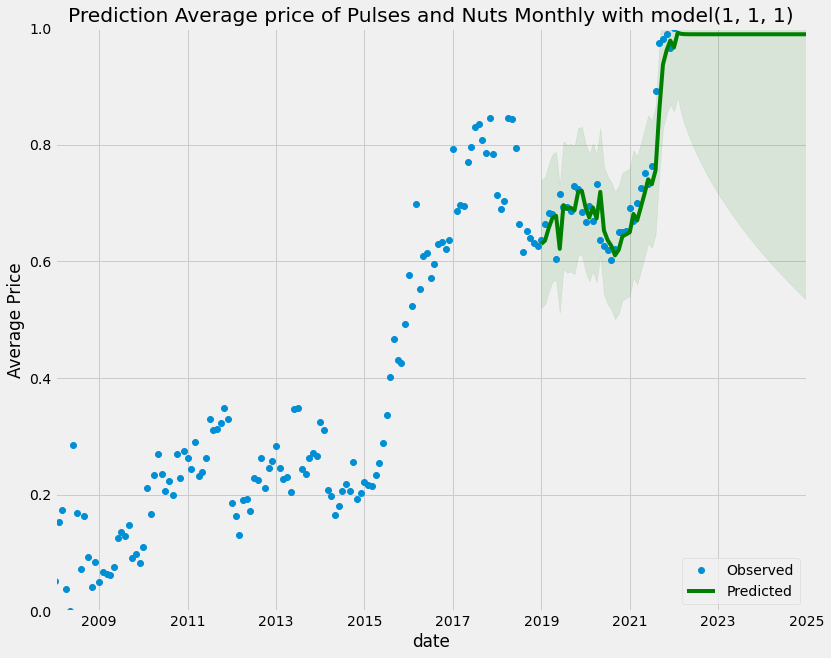

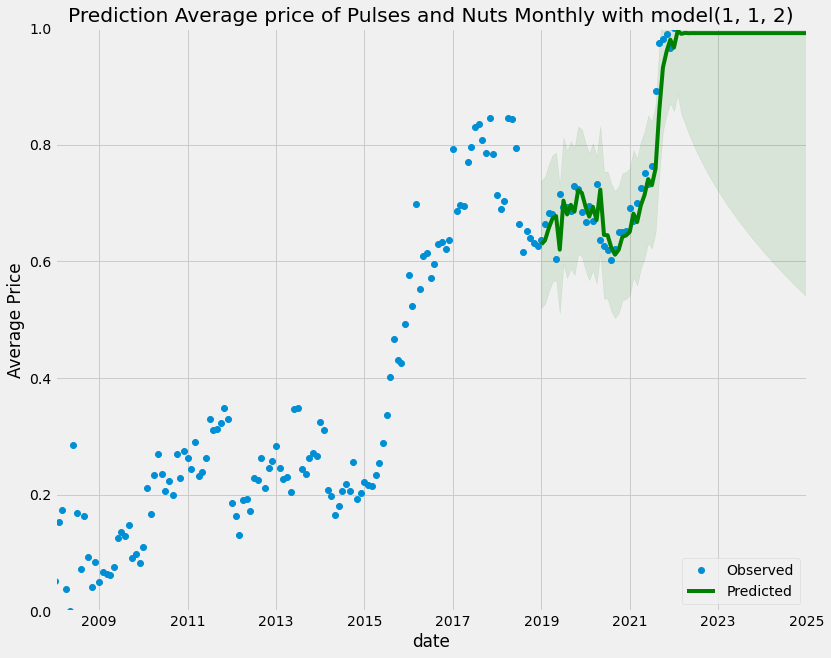

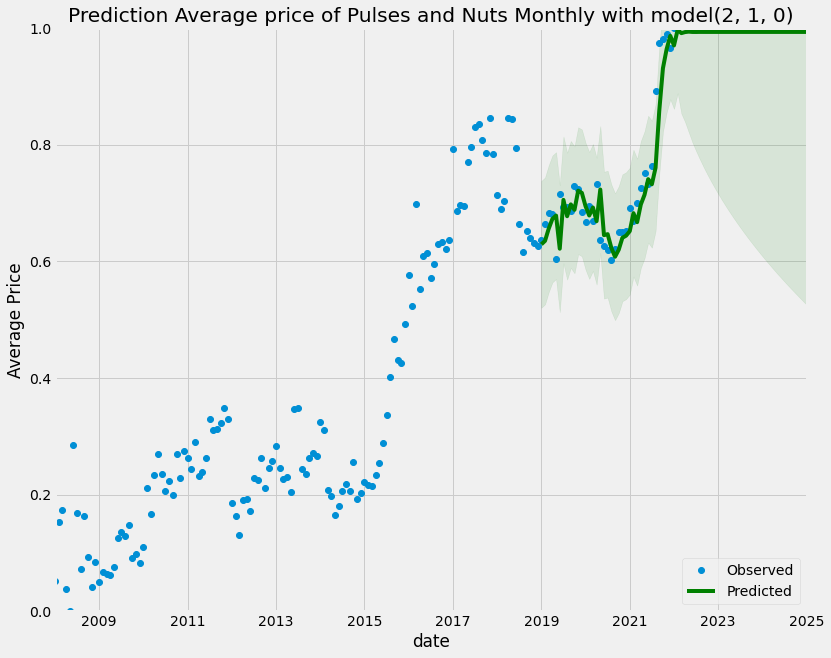

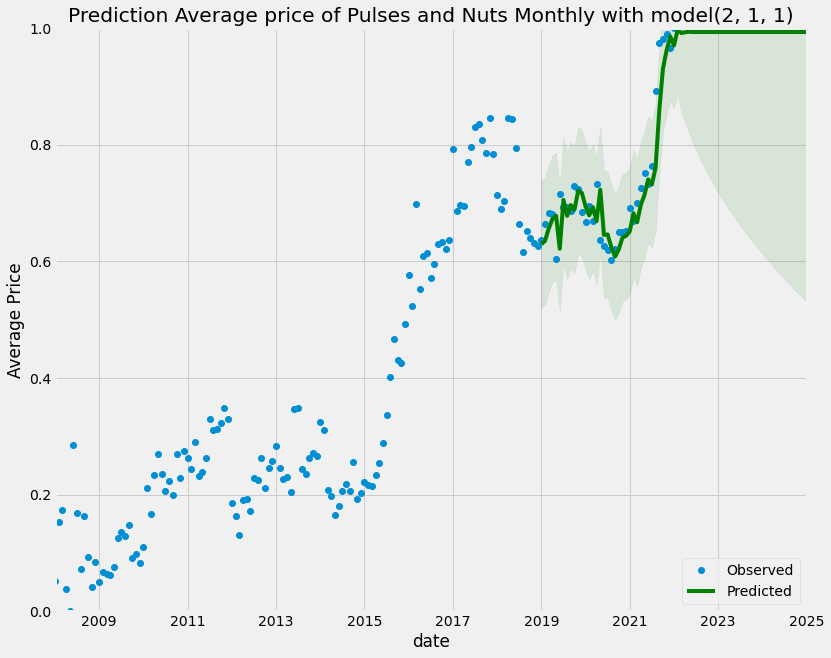

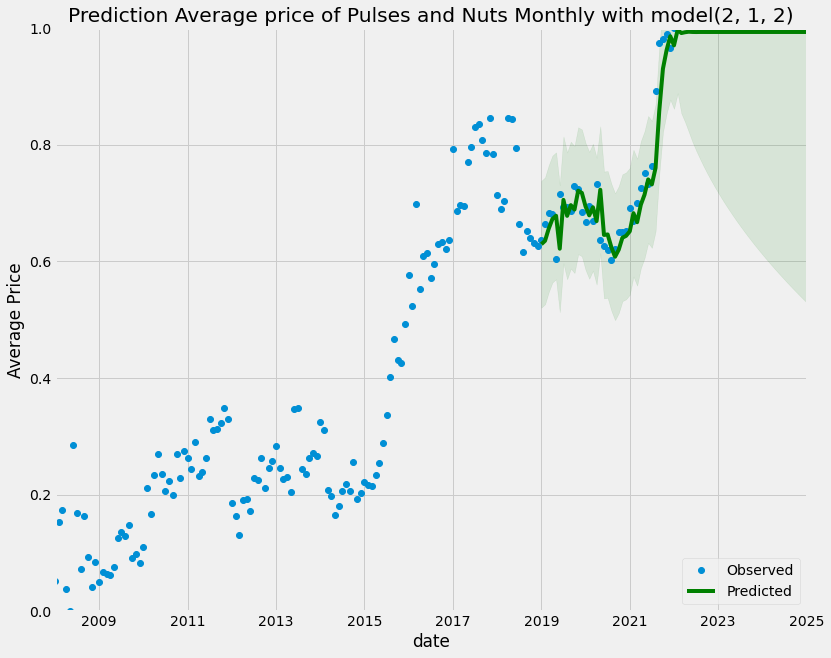

In [27]:
DPNM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DPNM, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Pulses and Nuts Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DPNM_models.append(model)

Now we choose (0,1,1)

In [28]:
DPNM_model = DPNM_models[1]

In [29]:
DPNM_pred_normalized = DPNM_model.predict(pred_st_date, pred_end_date)
DPNM_pred_normalized 

2019-01-01    0.628566
2019-02-01    0.634292
2019-03-01    0.656208
2019-04-01    0.675230
2019-05-01    0.680188
                ...   
2024-09-01    0.992460
2024-10-01    0.992460
2024-11-01    0.992460
2024-12-01    0.992460
2025-01-01    0.992460
Freq: MS, Name: predicted_mean, Length: 73, dtype: float64

We need to un-normalized the predicted value to get actual price

In [30]:
pred_date = DPNM_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2019-01-01', '2019-02-01', '2019-03-01', '2019-04-01',
               '2019-05-01', '2019-06-01', '2019-07-01', '2019-08-01',
               '2019-09-01', '2019-10-01', '2019-11-01', '2019-12-01',
               '2020-01-01', '2020-02-01', '2020-03-01', '2020-04-01',
               '2020-05-01', '2020-06-01', '2020-07-01', '2020-08-01',
               '2020-09-01', '2020-10-01', '2020-11-01', '2020-12-01',
               '2021-01-01', '2021-02-01', '2021-03-01', '2021-04-01',
               '2021-05-01', '2021-06-01', '2021-07-01', '2021-08-01',
               '2021-09-01', '2021-10-01', '2021-11-01', '2021-12-01',
               '2022-01-01', '2022-02-01', '2022-03-01', '2022-04-01',
               '2022-05-01', '2022-06-01', '2022-07-01', '2022-08-01',
               '2022-09-01', '2022-10-01', '2022-11-01', '2022-12-01',
               '2023-01-01', '2023-02-01', '2023-03-01', '2023-04-01',
               '2023-05-01', '2023-06-01', '2023-07-01', '2023-08-01',
      

In [31]:
DPNM_pred_normalized_df = pd.DataFrame(DPNM_pred_normalized)
DPNM_pred_normalized_df = DPNM_pred_normalized_df[:-1] # the last index doesn't need
DPNM_pred_normalized_df

,predicted_mean
2019-01-01,0.628566
2019-02-01,0.634292
2019-03-01,0.656208
2019-04-01,0.675230
2019-05-01,0.680188
...,...
2024-08-01,0.992460
2024-09-01,0.992460
2024-10-01,0.992460
2024-11-01,0.992460


##### Un-normalization data

In [32]:
DPNM_pred_act = scaler.inverse_transform(DPNM_pred_normalized_df)
DPNM_pred_act_df = pd.DataFrame(DPNM_pred_act)
DPNM_pred_act_df['date'] = pred_date
DPNM_pred_act_df.columns = ['Predicted Price', 'date']
DPNM_pred_act_df.set_index('date',  inplace=True)
DPNM_pred_act_df

,Predicted Price
date,
2019-01-01,1633.749103
2019-02-01,1643.794563
2019-03-01,1682.240715
2019-04-01,1715.609655
2019-05-01,1724.307042
...,...
2024-08-01,2272.107679
2024-09-01,2272.107679
2024-10-01,2272.107679
